# 26 - Rótulos (ground truth)

| | |
|---|---|
| **Tarefa do plano** | S2-09 - JRC mensal (2006–2021) + EMS/UNOSAT + amostras digitalizadas no QGIS (2022–2026) |
| **O que faz** | Organiza as 'respostas certas' que ensinam e avaliam os modelos |
| **Usa** | JRC mensal (notebook 10), séries de chuva e caudal, radar |
| **Produz** | `data/raw/labels/manual/labels.gpkg` (modelo), `reports/semana_2/26_meses_candidatos.csv` |

**Ideia simples.** Um modelo aprende com exemplos em que a resposta é conhecida:
"este píxel, neste mês, era água". Essas respostas são os rótulos. O projeto usa
três fontes:

| Fonte | Período | Papel |
|---|---|---|
| JRC mensal (automático, do Landsat) | 2006–2021 | treino dos dois modelos |
| Mapas públicos Copernicus EMS / UNOSAT | por evento | confirmar eventos, validar |
| Polígonos desenhados no QGIS pela equipa | 2022–2026 | validação **independente** |

**Regra de ouro.** Um modelo nunca é avaliado com rótulos que ele próprio gerou.
Por isso os anos 2022–2026 só podem ser avaliados com rótulos desenhados à mão
ou com mapas EMS/UNOSAT.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, drivers, features, rasters, series, training
from ete import grid as G

cfg = config.load_config()
P = cfg["processing"]
REPORTS = config.path(cfg, "reports", "semana_2")       # figuras e tabelas para o relatório
pd.set_option("display.float_format", "{:,.3f}".format)

import rasterio
frame = training.sampling_frame(cfg)

## 1. O que o JRC mensal consegue ver

Para cada mês: que parte do domínio foi observada e quanta água havia fora da
água permanente. Em meses de muitas nuvens o JRC vê pouco, mesmo havendo cheia.

meses com menos de metade do domínio observado: 50 de 192


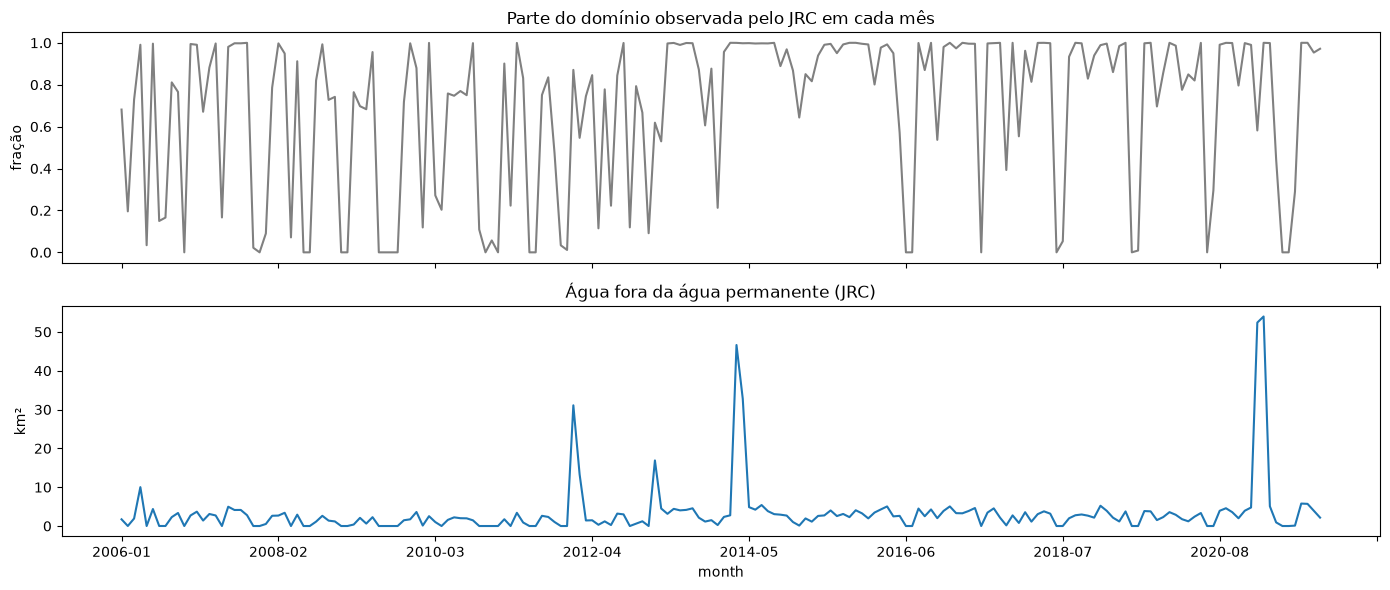

In [2]:
rows = []
domain, permanent = frame["domain"], frame["permanent"]
for month in rasters.available_months(cfg, "jrc_monthly"):
    with rasterio.open(rasters.monthly_file(cfg, "jrc_monthly", month)) as src:
        water = src.read(1)
    observed = domain & ((water == 1) | (water == 2))
    rows.append({"month": month, "jrc_observed_fraction": observed.sum() / domain.sum(),
                 "jrc_flood_km2": (observed & (water == 2) & ~permanent).sum() * 900 / 1e6})
jrc = pd.DataFrame(rows).set_index("month")
jrc.round(4).to_csv(drivers.table(cfg, "jrc_monthly_summary"))

fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
jrc["jrc_observed_fraction"].plot(ax=axes[0], color="grey"); axes[0].set_ylabel("fração"); axes[0].set_title("Parte do domínio observada pelo JRC em cada mês")
jrc["jrc_flood_km2"].plot(ax=axes[1], color="tab:blue"); axes[1].set_ylabel("km²"); axes[1].set_title("Água fora da água permanente (JRC)")
plt.tight_layout(); plt.savefig(REPORTS / "26_jrc_cobertura_e_agua.png", dpi=110)
print(f"meses com menos de metade do domínio observado: {(jrc['jrc_observed_fraction'] < 0.5).sum()} de {len(jrc)}")

## 2. Meses candidatos a evento de cheia

Junta quatro sinais independentes. Um mês é candidato quando pelo menos um deles
é extremo:

- chuva mensal na bacia entre os 10 % de meses mais chuvosos dos 20 anos;
- caudal máximo do mês entre os 10 % maiores dos 20 anos;
- área de água JRC fora da água permanente entre os 10 % maiores (até 2021).

O radar **não** entra como sinal: o notebook 20 mostrou que um limiar simples de
VV confunde seca com cheia. A coluna `s1_new_water_km2` fica na tabela só como
informação.

In [3]:
drv = drivers.load_monthly_drivers(cfg)
change = pd.read_csv(drivers.table(cfg, "s1_change_monthly"), index_col=0)[["s1_new_water_km2", "s1_offset_vv"]]
cand = drv[["rain_basin_mm", "rain_basin_pct", "q_mean", "q_max", "q_pct"]].join(jrc).join(change)
# limiares sobre todos os meses dos 20 anos (não por mês do calendário): um agosto
# "muito chuvoso para agosto" continua a ter pouca chuva e não é candidato a cheia
signals = pd.DataFrame({
    "chuva": cand["rain_basin_mm"] >= cand["rain_basin_mm"].quantile(0.9),
    "caudal": cand["q_max"] >= cand["q_max"].quantile(0.9),
    "jrc": cand["jrc_flood_km2"] >= cand["jrc_flood_km2"].quantile(0.9),
})
cand["sinais"] = signals.apply(lambda r: "+".join(k for k, v in r.items() if v), axis=1)
cand["n_sinais"] = signals.sum(axis=1)
for key in ["landsat", "sentinel1", "sentinel2"]:
    cand[f"tem_{key}"] = cand.index.isin(rasters.available_months(cfg, key))
cand["rotulo_disponivel"] = np.where(cand.index <= "2021-12", "JRC mensal", "desenhar no QGIS / EMS")
candidatos = cand[cand["n_sinais"] >= 1].sort_values(["n_sinais", "rain_basin_mm"], ascending=False)
candidatos.round(2).to_csv(REPORTS / "26_meses_candidatos.csv")
print(f"{len(candidatos)} meses candidatos, {int((candidatos['n_sinais'] >= 2).sum())} com dois ou mais sinais")
candidatos[candidatos["n_sinais"] >= 2].round(1)

53 meses candidatos, 14 com dois ou mais sinais


,rain_basin_mm,rain_basin_pct,q_mean,q_max,q_pct,jrc_observed_fraction,jrc_flood_km2,s1_new_water_km2,s1_offset_vv,sinais,n_sinais,tem_landsat,tem_sentinel1,tem_sentinel2,rotulo_disponivel
month,,,,,,,,,,,,,,,
2021-02,289.200,95.200,407.500,548.900,90.500,0.600,52.400,21.600,0.700,chuva+caudal+jrc,3,True,True,True,JRC mensal
2021-01,240.500,95.200,204.300,"1,229.700",76.200,1.000,4.800,4.500,0.800,chuva+caudal+jrc,3,True,True,True,JRC mensal
2014-03,212.000,90.500,371.500,727.800,95.200,1.000,46.600,NaN,NaN,chuva+caudal+jrc,3,True,False,False,JRC mensal
2023-02,425.700,100.000,573.300,"2,370.700",100.000,NaN,NaN,20.600,0.900,chuva+caudal,2,True,True,True,desenhar no QGIS / EMS
2026-01,355.300,100.000,"1,117.800","2,986.900",100.000,NaN,NaN,26.300,1.300,chuva+caudal,2,True,True,True,desenhar no QGIS / EMS
2026-03,227.500,100.000,314.100,405.800,90.500,NaN,NaN,36.700,0.900,chuva+caudal,2,True,True,True,desenhar no QGIS / EMS
2013-01,218.900,90.500,474.100,"1,961.500",95.200,0.100,0.000,NaN,NaN,chuva+caudal,2,True,False,False,JRC mensal
2006-03,198.200,85.700,400.500,622.600,100.000,0.700,1.900,NaN,NaN,chuva+caudal,2,True,False,False,JRC mensal
2017-01,194.500,81.000,91.800,183.400,33.300,1.000,5.000,2.600,0.700,chuva+jrc,2,True,True,True,JRC mensal


Esta lista é uma **sugestão calculada**, não uma lista de eventos confirmados.
Cada evento tem de ser confirmado numa fonte pública (Copernicus EMS Rapid
Mapping, UNOSAT, relatórios do INGD) e registado em
`data/raw/labels/flood_events/flood_events_catalogue.csv` com a referência.

## 3. Meses a digitalizar no QGIS (2022 em diante)

Depois de 2021 não há JRC mensal. Para avaliar os modelos nesses anos são
precisos polígonos desenhados à mão. A tabela indica os meses prioritários e que
imagens existem para os desenhar.

In [4]:
a_digitalizar = candidatos[candidatos.index >= "2022-01"][["sinais", "rain_basin_mm", "q_max", "s1_new_water_km2", "tem_sentinel1", "tem_sentinel2"]].round(1)
secos = cand[(cand.index >= "2022-01") & (cand["rain_basin_pct"] <= 30) & cand["tem_sentinel2"]].nsmallest(3, "rain_basin_mm")
print("Meses de cheia a digitalizar:"); display(a_digitalizar)
print("Meses secos de controlo (para ter exemplos de 'não é água' sem ambiguidade):", list(secos.index))

Meses de cheia a digitalizar:


,sinais,rain_basin_mm,q_max,s1_new_water_km2,tem_sentinel1,tem_sentinel2
month,,,,,,
2023-02,chuva+caudal,425.700,"2,370.700",20.600,True,True
2026-01,chuva+caudal,355.300,"2,986.900",26.300,True,True
2026-03,chuva+caudal,227.500,405.800,36.700,True,True
2025-02,chuva+caudal,187.000,584.100,3.800,True,True
2023-12,chuva,228.500,194.400,9.200,True,True
2025-11,chuva,221.900,170.200,4.400,True,True
2024-03,chuva,217.200,80.200,5.800,True,True
2022-12,chuva,170.400,220.700,4.900,True,True
2022-01,caudal,163.000,439.600,3.400,True,True


Meses secos de controlo (para ter exemplos de 'não é água' sem ambiguidade): ['2024-07', '2024-05', '2022-08']


## 4. Ficheiro de rótulos manuais (`labels.gpkg`)

A célula cria o ficheiro vazio, com os campos certos, se ainda não existir.

**Como digitalizar (Agostinho)**

1. No QGIS, abrir a imagem do mês: o Sentinel-1 (`data/raw/radar/sentinel1/...`,
   banda VV, água a escuro) e, se não tiver nuvens, o Sentinel-2. Os rasters de
   índices exportados pelo notebook 20 também ajudam.
2. Abrir `data/raw/labels/manual/labels.gpkg`, camada `amostras`, e ativar a edição.
3. Desenhar polígonos **pequenos e seguros**: só onde a classe é evidente. Deixar
   as margens e as zonas duvidosas de fora.
4. Preencher os campos de cada polígono (tabela abaixo).
5. Desenhar as duas classes em cada mês, incluindo "não é água" em terreno baixo
   junto ao rio, que é o caso difícil.

| Campo | Valores |
|---|---|
| `class` | `water` ou `non_water` |
| `month` | mês da imagem, formato `AAAA-MM` |
| `event_id` | código do evento no catálogo, se houver |
| `source` | imagem usada (ex.: `S1 VV 2023-02`) |
| `author` | quem desenhou |
| `confidence` | `alta` ou `media` |
| `notes` | observações |

Os notebooks 27 e 28 leem este ficheiro sozinhos: quando houver polígonos, basta
voltar a corrê-los e as linhas entram na tabela com `label_source = manual`.

In [5]:
import geopandas as gpd

labels_file = config.path(cfg, "labels_manual", "labels.gpkg")
if not labels_file.exists():
    empty = gpd.GeoDataFrame({c: pd.Series(dtype="str") for c in ["class", "month", "event_id", "source", "author", "confidence", "notes"]},
                             geometry=gpd.GeoSeries([], crs=cfg["grid"]["crs"]))
    empty.to_file(labels_file, layer="amostras", driver="GPKG", geometry_type="Polygon")
    print("ficheiro vazio criado:", labels_file.relative_to(ROOT))
labels = gpd.read_file(labels_file, layer="amostras")
print(f"{len(labels)} polígonos em labels.gpkg")
labels.groupby(["month", "class"]).size().unstack(fill_value=0) if len(labels) else "ainda sem polígonos"

0 polígonos em labels.gpkg


'ainda sem polígonos'

## 5. Rótulos de referência do Copernicus EMS (cheia de janeiro de 2026)

O serviço de emergência do Copernicus mapeou a cheia de janeiro de 2026
(ativação **EMSR857**). A área "AOI06 Palmeira" cobre 58 % do distrito de
Marracuene, com quatro mapas de delineação entre 17 e 24 de janeiro, feitos com
Sentinel-1, COSMO-SkyMed e ICEYE. Os dois últimos são satélites que este projeto
não usa: é uma referência **independente**, feita por um serviço operacional.

Os pacotes estão em `data/raw/labels/ems_unosat/EMSR857_AOI06_Palmeira/`. A
célula transforma-os em polígonos de duas classes:

- `water`: alagado em pelo menos uma das datas, encolhido 30 m para deixar de
  fora a margem incerta;
- `non_water`: dentro da área analisada pelo EMS e a mais de 100 m de qualquer
  cheia observada ou modelada.

A faixa entre as duas fica sem rótulo de propósito: o radar pode não ver água
debaixo de vegetação ou entre casas.

,count,sum
class,,
non_water,21,199.500
water,99,288.600


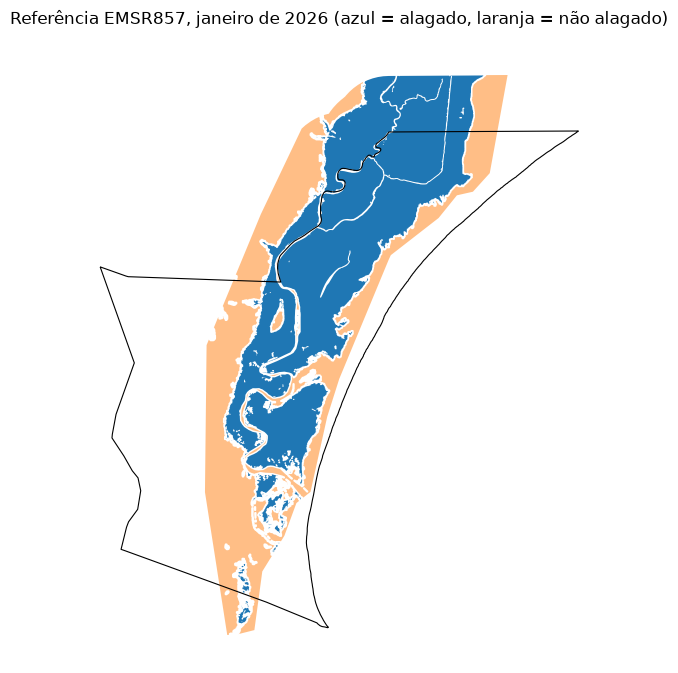

In [6]:
from ete import labels as ems

products = sorted((config.path(cfg, "ems_unosat", mkdir=False) / "EMSR857_AOI06_Palmeira").glob("EMSR857_AOI06_DEL_*/"))
if products:
    polygons = ems.ems_reference_polygons(cfg, products, month="2026-01", event_id="EMSR857")
    ems.write_ems_labels(cfg, polygons)
    display(polygons.assign(km2=polygons.area / 1e6).groupby("class")["km2"].agg(["count", "sum"]).round(1))

    district = G.load_aoi(cfg, "district").to_crs(cfg["grid"]["crs"])
    ax = district.boundary.plot(color="black", linewidth=0.8, figsize=(7, 8))
    polygons[polygons["class"] == "non_water"].plot(ax=ax, color="tab:orange", alpha=0.5)
    polygons[polygons["class"] == "water"].plot(ax=ax, color="tab:blue")
    ax.set_title("Referência EMSR857, janeiro de 2026 (azul = alagado, laranja = não alagado)"); ax.set_axis_off()
    plt.savefig(REPORTS / "26_ems_emsr857_referencia.png", dpi=110)
else:
    print("pacotes EMSR857 não encontrados: descarregar de https://rapidmapping.emergency.copernicus.eu/EMSR857")

**Limites desta referência**

- Vale para janeiro de 2026 e só para a parte do distrito dentro da área
  analisada pelo EMS (a planície do Incomáti; o sul do distrito fica de fora).
- "Alagado" significa alagado em alguma data entre 17 e 24 de janeiro. As
  composições mensais do projeto são a mediana do mês inteiro; metade das
  passagens de janeiro são anteriores à cheia. Esta referência mede portanto
  também o que se perde por trabalhar com composições mensais.
- A ativação de fevereiro de 2023 (**EMSR650**) cobre o distrito, mas os mapas de
  12 a 14 de fevereiro não mostram nenhuma área alagada dentro da zona de
  estudo: nessas datas a cheia estava a montante (Boane, Moamba). Não dá rótulos
  para Marracuene.

## 6. Estado dos rótulos

| Período | Rótulo | Estado |
|---|---|---|
| 2006–2021 | JRC mensal | pronto (192 meses) |
| janeiro de 2026 | Copernicus EMS (EMSR857) | pronto: referência independente |
| outros meses de 2022–2026 | polígonos QGIS | por fazer |

O teste independente dos modelos em 2022–2026 assenta, para já, num único
evento: janeiro de 2026. É o maior dos 20 anos, o que o torna um bom teste, mas
um evento só não chega para afirmar que o modelo funciona sempre.